# My Letterboxd film taste: analysis and rating prediction

I joined the 355 films I have rated on Letterboxd with information from TMDB and looked at two questions: which films do I rate higher, and can I predict the rating I would give a film I haven't seen yet?

The notebook has three parts and has to be run in order, because Part 1 builds the analysis table the later parts read:

1. **Data cleaning:** joining my ratings with TMDB data, features, `analysis_table.csv`
2. **Exploratory analysis and tests:** decades, genres, agreement with TMDB, language, time
3. **Rating prediction:** 11 models, repeated and nested cross-validation, ordinal logistic regression, an 80/20 hold-out test, my watchlist

The nested cross-validation in Part 3 takes a few minutes.

## Part 1: Data cleaning

In this part I join my Letterboxd ratings with the film information I pulled from TMDB, so the next two parts can work from a single table.

Inputs: `data/raw/ratings.csv`, `data/raw/likes_films.csv`, `data/processed/films_enriched.csv`
Output: `data/processed/analysis_table.csv`

> This product uses the TMDB API but is not endorsed or certified by TMDB.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path('..').resolve()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'

ratings = pd.read_csv(RAW / 'ratings.csv', parse_dates=['Date'])
likes = pd.read_csv(RAW / 'likes_films.csv')
films = pd.read_csv(PROC / 'films_enriched.csv')
print(ratings.shape, likes.shape, films.shape)
ratings.head()

(358, 5) (77, 4) (700, 16)


,Date,Name,Year,Letterboxd URI,Rating
0,2023-08-31,Knives Out,2019,https://boxd.it/jWEA,4.5
1,2022-12-05,Se7en,1995,https://boxd.it/29zs,5.0
2,2022-12-06,Inception,2010,https://boxd.it/1skk,4.0
3,2022-12-06,2001: A Space Odyssey,1968,https://boxd.it/2bf0,4.0
4,2023-07-04,Blade Runner 2049,2017,https://boxd.it/b8wK,4.0


### 1. A first look at the data

Before joining anything I check the ratings file for duplicate films, missing values or odd ratings.

In [2]:
print('Duplicate films (ratings):', ratings['Letterboxd URI'].duplicated().sum())
print('Missing values:\n', ratings.isna().sum())
print('Rating values:', sorted(ratings['Rating'].unique()))

Duplicate films (ratings): 0
Missing values:
 Date              0
Name              0
Year              0
Letterboxd URI    0
Rating            0
dtype: int64
Rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


### 2. Joining ratings with TMDB

Most films that fail to join will be TV series or episodes, which TMDB's film search doesn't return. This project is about film taste, so I drop them. I print which ones are dropped so nothing slips by.

In [3]:
df = ratings.rename(columns={'Letterboxd URI': 'uri', 'Name': 'name', 'Year': 'year',
                             'Rating': 'rating', 'Date': 'rated_date'})
df = df.merge(films.drop(columns=['name', 'year']), on='uri', how='left', indicator=True)

dropped = df[df['_merge'] == 'left_only']
print(f'Not matched on TMDB (left out): {len(dropped)}')
print(dropped['name'].tolist())

df = df[df['_merge'] == 'both'].drop(columns='_merge').reset_index(drop=True)
print('Films in the analysis:', len(df))

Not matched on TMDB (left out): 3
['11.22.63', "The Making of 'Dunkirk'", 'Black Mirror: Hang the DJ']
Films in the analysis: 355


### 3. Features

Here I derive the columns I'll use in the tests and the models.

In [4]:
# films I gave a heart on Letterboxd
df['liked'] = df['uri'].isin(likes['Letterboxd URI']).astype(int)

# time: decade, how old the film was when I rated it, the year I rated it
df['decade'] = (df['year'] // 10) * 10
df['film_age_at_rating'] = df['rated_date'].dt.year - df['year']
df['rated_year'] = df['rated_date'].dt.year

# language and country
df['is_english'] = (df['original_language'] == 'en').astype(int)
df['primary_country'] = df['countries'].fillna('').str.split('|').str[0].replace('', np.nan)
df['is_turkish'] = (df['original_language'] == 'tr').astype(int)

# director: if there are several, I keep the first
df['director'] = df['directors'].fillna('').str.split('|').str[0].replace('', np.nan)

# genres: one 0/1 column per genre (a film can have several)
genre_dummies = df['genres'].fillna('').str.get_dummies(sep='|').add_prefix('g_')
df['n_genres'] = genre_dummies.sum(axis=1)
df = pd.concat([df, genre_dummies], axis=1)

# vote count and popularity are very skewed, so I take logs
df['log_votes'] = np.log1p(df['tmdb_vote_count'])
df['log_popularity'] = np.log1p(df['popularity'])

# classification target: "loved it" if I gave 4 or more
df['loved'] = (df['rating'] >= 4).astype(int)
df.shape

(355, 49)

### 4. Checks

I look at missing values, the runtime column and the genre counts. I want to catch rare genres and zero-length films here.

In [5]:
print(df[['rating','year','runtime','tmdb_vote_average','tmdb_vote_count','n_genres']].describe().round(2))
print('\nMissing values:')
print(df[['runtime','primary_country','director','tmdb_vote_average']].isna().sum())
print('\nZero runtime:', (df['runtime'] == 0).sum())
print('\nFilms per genre:')
print(genre_dummies.sum().sort_values(ascending=False))

       rating     year  runtime  tmdb_vote_average  tmdb_vote_count  n_genres
count  355.00   355.00   355.00             355.00           355.00    355.00
mean     3.66  2007.40   125.90               7.46         10119.50      2.48
std      0.91    14.71    32.16               0.69          8593.58      0.83
min      0.50  1927.00    23.00               4.31            18.00      1.00
25%      3.00  2000.00   105.00               7.03          3492.50      2.00
50%      4.00  2011.00   122.00               7.52          7883.00      3.00
75%      4.50  2018.00   139.00               7.99         15280.50      3.00
max      5.00  2026.00   432.00               8.74         41996.00      5.00

Missing values:
runtime              0
primary_country      1
director             1
tmdb_vote_average    0
dtype: int64

Zero runtime: 0

Films per genre:
g_Drama              206
g_Thriller            82
g_Science Fiction     77
g_Action              76
g_Adventure           72
g_Comedy        

### 5. Notes

- A director I've seen only one film by doesn't tell a model anything. In the modelling I'd only give directors with at least 3 films their own category and put the rest into "other".
- Ratings go up in half stars and form an ordinal scale, so I use non-parametric tests.
- A film with a runtime of 0 counts as missing. This cell sets it to NaN and saves the table.

In [6]:
df.loc[df['runtime'] == 0, 'runtime'] = np.nan
out = PROC / 'analysis_table.csv'
df.to_csv(out, index=False, encoding='utf-8-sig')
print('Saved:', out, df.shape)

Saved: D:\claude\letterboxd-projesi\data\processed\analysis_table.csv (355, 49)


## Part 2: Exploratory analysis and tests

Here I look at my own ratings and try to answer: which genres, periods and countries do I rate higher, how closely do I agree with the TMDB average, and has my taste changed over time?

I have 355 rated films. That's not many, so I print the group sizes in every comparison. Ratings form an ordinal scale in half-star steps, so instead of t-tests I use non-parametric tests (Kruskal-Wallis, Mann-Whitney, Spearman). I test many genres on the same data, so I adjust the p-values with Benjamini-Hochberg.

Input: `data/processed/analysis_table.csv`

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path('..').resolve()
FIG = ROOT / 'reports' / 'figures_en'
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(42)

df = pd.read_csv(ROOT / 'data' / 'processed' / 'analysis_table.csv', parse_dates=['rated_date'])
genre_cols = [c for c in df.columns if c.startswith('g_')]
print(df.shape)

def boot_ci(x, n=5000, alpha=0.05):
    x = np.asarray(x)
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

(355, 49)


### 1. How my ratings are distributed

count    355.00
mean       3.66
std        0.91
min        0.50
25%        3.00
50%        4.00
75%        4.50
max        5.00
Name: rating, dtype: float64

Median: 4.0 | 95% bootstrap CI of the mean: [3.57 3.76]


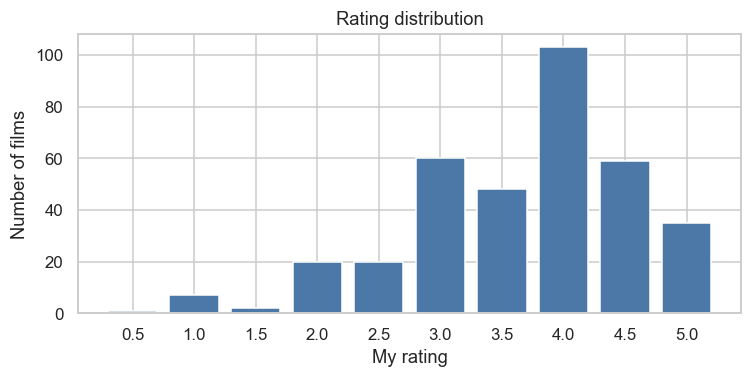

In [8]:
print(df['rating'].describe().round(2))
print('\nMedian:', df['rating'].median(), '| 95% bootstrap CI of the mean:', boot_ci(df['rating']).round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
order = np.arange(0.5, 5.5, 0.5)
counts = df['rating'].value_counts().reindex(order, fill_value=0)
ax.bar(order, counts.values, width=0.4, color='#4c78a8')
ax.set_xticks(order)
ax.set_xlabel('My rating')
ax.set_ylabel('Number of films')
ax.set_title('Rating distribution')
fig.tight_layout()
fig.savefig(FIG / '01_rating_distribution.png')
plt.show()

### 2. By decade

I put everything before 1980 in one group, because I've seen very few films from those years.

       count  mean  median
<1980     19  4.37    4.50
1980s     12  4.33    4.25
1990s     54  4.15    4.00
2000s     77  3.87    4.00
2010s    131  3.49    3.50
2020s     62  3.02    3.00

Kruskal-Wallis: H = 74.89, p = 0.000


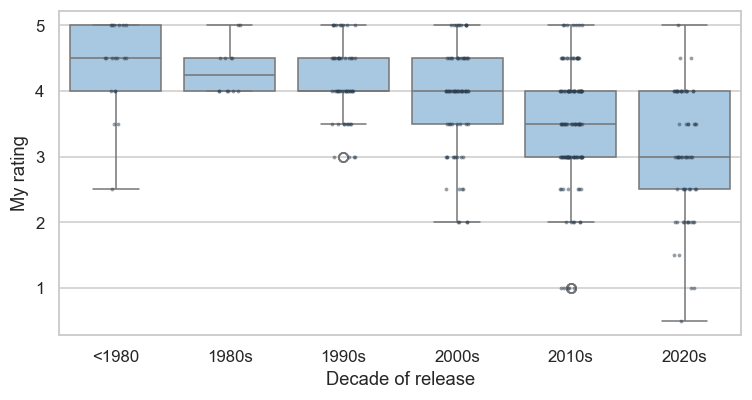

In [9]:
df['decade_grp'] = df['decade'].where(df['decade'] >= 1980, 1970).astype(int)
dec = df.groupby('decade_grp')['rating'].agg(['count', 'mean', 'median']).round(2)
dec.index = ['<1980' if d == 1970 else f'{d}s' for d in dec.index]
print(dec)

groups = [g['rating'].values for _, g in df.groupby('decade_grp')]
H, p = stats.kruskal(*groups)
print(f'\nKruskal-Wallis: H = {H:.2f}, p = {p:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.boxplot(data=df, x='decade_grp', y='rating', color='#9ecae9', ax=ax)
sns.stripplot(data=df, x='decade_grp', y='rating', color='#2c3e50', size=2.5, alpha=0.5, ax=ax)
ax.set_xticks(range(len(dec)))
ax.set_xticklabels(dec.index)
ax.set_xlabel('Decade of release')
ax.set_ylabel('My rating')
fig.tight_layout()
fig.savefig(FIG / '02_decades.png')
plt.show()

### 3. By genre

A film can belong to several genres, so the groups aren't independent. I compare each genre as "films in this genre vs. all the others", and only look at genres with at least 15 films.

          genre   n  mean  ci_low  ci_high  mean_others   diff     p  p_adj
      Animation  23 4.261   4.065    4.457        3.623  0.637 0.001  0.004
          Crime  54 3.954   3.731    4.176        3.613  0.341 0.008  0.017
         Family  20 3.900   3.525    4.225        3.651  0.249 0.172  0.286
        History  16 3.875   3.469    4.219        3.655  0.220 0.394  0.537
          Drama 206 3.842   3.733    3.951        3.419  0.423 0.000  0.001
        Mystery  36 3.819   3.486    4.125        3.647  0.172 0.145  0.272
        Romance  48 3.750   3.531    3.958        3.651  0.099 0.745  0.798
            War  17 3.706   3.324    4.088        3.663  0.043 0.950  0.950
        Fantasy  44 3.659   3.341    3.955        3.666 -0.007 0.722  0.798
       Thriller  82 3.628   3.433    3.823        3.676 -0.048 0.727  0.798
         Comedy  56 3.571   3.366    3.777        3.682 -0.111 0.215  0.322
      Adventure  72 3.361   3.132    3.590        3.742 -0.381 0.004  0.009
         Act

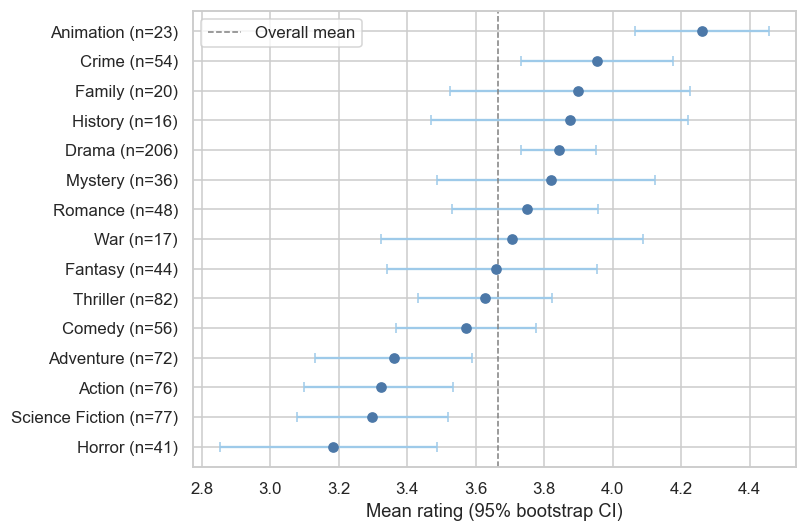

In [10]:
rows = []
for c in genre_cols:
    mask = df[c] == 1
    n = int(mask.sum())
    if n < 15:
        continue
    a, b = df.loc[mask, 'rating'], df.loc[~mask, 'rating']
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    lo, hi = boot_ci(a)
    rows.append({'genre': c[2:], 'n': n, 'mean': a.mean(), 'ci_low': lo, 'ci_high': hi,
                 'mean_others': b.mean(), 'diff': a.mean() - b.mean(), 'p': p})
gen = pd.DataFrame(rows)
gen['p_adj'] = multipletests(gen['p'], method='fdr_bh')[1]
gen = gen.sort_values('mean', ascending=False).reset_index(drop=True)
print(gen.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(gen))[::-1]
ax.errorbar(gen['mean'], y, xerr=[gen['mean'] - gen['ci_low'], gen['ci_high'] - gen['mean']],
            fmt='o', color='#4c78a8', ecolor='#9ecae9', capsize=3)
ax.axvline(df['rating'].mean(), color='gray', ls='--', lw=1, label='Overall mean')
ax.set_yticks(y)
ax.set_yticklabels([f"{t} (n={n})" for t, n in zip(gen['genre'], gen['n'])])
ax.set_xlabel('Mean rating (95% bootstrap CI)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / '03_genres.png')
plt.show()

### 4. My rating vs. the TMDB rating

Do I like the films the crowd likes? I check with Spearman correlations.

           variable    rho  ci_low  ci_high     p  p_adj
TMDB average rating  0.599   0.521    0.667 0.000  0.000
     log vote count  0.110   0.006    0.212 0.038  0.057
     log popularity  0.188   0.088    0.290 0.000  0.001
      runtime (min)  0.091  -0.019    0.200 0.086  0.103
       release year -0.475  -0.554   -0.390 0.000  0.000
   number of genres -0.062  -0.163    0.042 0.241  0.241


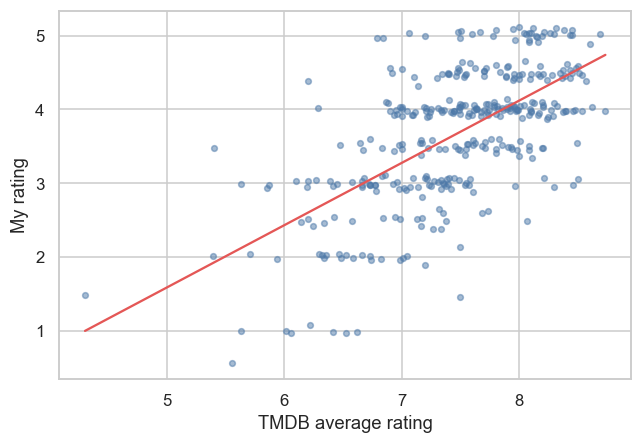

In [11]:
cands = {'TMDB average rating': 'tmdb_vote_average', 'log vote count': 'log_votes',
         'log popularity': 'log_popularity', 'runtime (min)': 'runtime', 'release year': 'year',
         'number of genres': 'n_genres'}
res = []
for label, col in cands.items():
    sub = df[['rating', col]].dropna()
    r, p = stats.spearmanr(sub['rating'], sub[col])
    # bootstrap interval
    idx = rng.integers(0, len(sub), size=(2000, len(sub)))
    rs = [stats.spearmanr(sub['rating'].values[i], sub[col].values[i])[0] for i in idx]
    res.append({'variable': label, 'rho': r, 'ci_low': np.quantile(rs, .025), 'ci_high': np.quantile(rs, .975), 'p': p})
corr = pd.DataFrame(res)
corr['p_adj'] = multipletests(corr['p'], method='fdr_bh')[1]
print(corr.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4.2))
jit = rng.normal(0, 0.06, len(df))
ax.scatter(df['tmdb_vote_average'], df['rating'] + jit, s=14, alpha=0.5, color='#4c78a8')
m, b = np.polyfit(df['tmdb_vote_average'], df['rating'], 1)
xs = np.linspace(df['tmdb_vote_average'].min(), df['tmdb_vote_average'].max(), 50)
ax.plot(xs, m * xs + b, color='#e45756')
ax.set_xlabel('TMDB average rating')
ax.set_ylabel('My rating')
fig.tight_layout()
fig.savefig(FIG / '04_tmdb_vs_me.png')
plt.show()

### 5. English vs. other languages

In [12]:
eng = df.loc[df['is_english'] == 1, 'rating']
non = df.loc[df['is_english'] == 0, 'rating']
print(f'English: n={len(eng)}, mean={eng.mean():.2f} | Other: n={len(non)}, mean={non.mean():.2f}')
u, p = stats.mannwhitneyu(eng, non)
print(f'Mann-Whitney U={u:.0f}, p={p:.3f}')
print('\nLanguages I watch most:')
print(df.groupby('original_language')['rating'].agg(['count', 'mean']).sort_values('count', ascending=False).head(6).round(2))

English: n=283, mean=3.60 | Other: n=72, mean=3.93
Mann-Whitney U=7632, p=0.001

Languages I watch most:
                   count  mean
original_language             
en                   283  3.60
tr                    26  3.54
ja                    12  4.42
fr                     9  4.22
fa                     4  4.38
de                     4  4.12


### 6. Over time: has my taste changed?

I look at the mean rating by the year I rated the film, and also at whether the age of the films I rate has changed. 2022 only covers December, and 2026 is only part of the year.

              n  mean  median_film_year
rated_year                             
2022         46  3.78            2007.0
2023        132  3.44            2014.0
2024         88  3.72            2011.0
2025         63  3.96            2004.0
2026         26  3.69            2014.0

Kruskal-Wallis (by year rated): H=17.12, p=0.002
Spearman (date, rating): rho=0.088, p=0.097


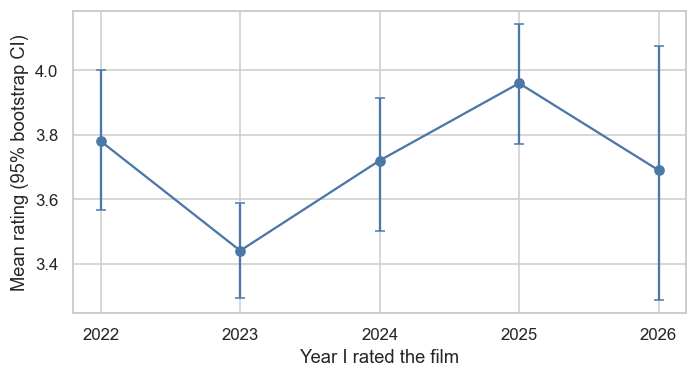

In [13]:
yr = df.groupby('rated_year').agg(n=('rating', 'size'), mean=('rating', 'mean'),
                                  median_film_year=('year', 'median')).round(2)
print(yr)
H, p = stats.kruskal(*[g['rating'].values for _, g in df.groupby('rated_year')])
print(f'\nKruskal-Wallis (by year rated): H={H:.2f}, p={p:.3f}')
r, p = stats.spearmanr(df['rated_date'].map(pd.Timestamp.toordinal), df['rating'])
print(f'Spearman (date, rating): rho={r:.3f}, p={p:.3f}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ci = [boot_ci(g['rating']) for _, g in df.groupby('rated_year')]
ax.errorbar(yr.index, yr['mean'], yerr=[yr['mean'] - [c[0] for c in ci], [c[1] for c in ci] - yr['mean']],
            fmt='o-', color='#4c78a8', capsize=3)
ax.set_xticks(yr.index)
ax.set_xlabel('Year I rated the film')
ax.set_ylabel('Mean rating (95% bootstrap CI)')
fig.tight_layout()
fig.savefig(FIG / '05_over_time.png')
plt.show()

### 7. Do my hearts agree with my ratings?

In [14]:
print(df.groupby('rating')['liked'].agg(['count', 'mean']).round(2).T)
print('\nMean rating of hearted films:', round(df.loc[df['liked'] == 1, 'rating'].mean(), 2),
      '| of the rest:', round(df.loc[df['liked'] == 0, 'rating'].mean(), 2))
print('Films rated 4 or more without a heart:', int(((df['rating'] >= 4) & (df['liked'] == 0)).sum()))

rating  0.5  1.0  1.5   2.0   2.5   3.0   3.5     4.0    4.5    5.0
count   1.0  7.0  2.0  20.0  20.0  60.0  48.0  103.00  59.00  35.00
mean    0.0  0.0  0.0   0.0   0.0   0.0   0.0    0.08   0.63   0.91

Mean rating of hearted films: 4.66 | of the rest: 3.39
Films rated 4 or more without a heart: 120


### 8. What came out of it?

The numbers come from the cells above. With small n the intervals are wide, so I don't read any of this as a firm verdict.

**I rate older films higher.** My mean is 4.37 before 1980, 4.15 for the 1990s, 3.87 for the 2000s, 3.49 for the 2010s and 3.02 for the 2020s. Kruskal-Wallis shows this isn't chance (H = 74.9, p < 0.001), and the Spearman correlation between release year and rating is -0.48. Part of this may be selection: from older decades I watch the films that are already praised in lists, while I pick new films more or less at random. So "I'm selective with older films" is a fairer reading than "older films are better".

**Genres.** After adjusting the p-values, Animation (4.26), Crime (3.95) and Drama (3.84) are higher than the rest. Horror (3.18), Science Fiction (3.30), Action (3.32) and Adventure (3.36) are lower. Romance, Thriller, Comedy, Fantasy, War, History, Mystery and Family don't differ. Horror has 41 films and a wide interval (2.85 to 3.49), so I'd be careful there.

**I agree with TMDB.** Spearman rho between my rating and the TMDB average is 0.60 (95% interval 0.52 to 0.67). The relationship with vote count is weak (0.11), with popularity a bit stronger (0.19). Runtime and number of genres show no clear relationship.

**I rate non-English films higher.** My mean is 3.60 for English-language films and 3.93 for other languages (Mann-Whitney p = 0.001). The Japanese (n = 12) and French (n = 9) means are above 4, but those groups are small. Turkish films (n = 26) average 3.54, close to English.

**Over time.** The means differ by the year I rated the film (Kruskal-Wallis p = 0.002), but there's no steady rise or fall: 3.78 in 2022, 3.44 in 2023, 3.72 in 2024, 3.96 in 2025. The Spearman correlation between date and rating is 0.09 (p = 0.10). The low 2023 may be because I watched more new films that year: the median release year was 2014 in 2023 and 2004 in 2025.

**Hearts and ratings.** I gave a heart to 63% of the films I rated 4.5 and 91% of those I rated 5, but only 8% of the 4s. There are 120 films I rated 4 or more without a heart, so the heart means "loved it".

#### What this means for the modelling

- Release year and TMDB rating are the two strongest candidate features. Genres and release year may be tangled up (sci-fi and action are more common among new films), so I'll handle them together in the model.
- 355 films is not much, so I'll use repeated cross-validation and compare every model with a simple baseline that predicts the mean rating.
- I won't use the heart as a feature: it's created together with the rating and would leak.

## Part 3: Rating prediction

The question: without having seen a film, can I predict the rating I'd give it from its TMDB information alone?

With only 355 films I go carefully:
- I evaluate with 5-fold cross-validation repeated 10 times (50 different train/test splits). I don't want to rely on the luck of a single split.
- I compare every model with a **baseline** that predicts my mean rating for everyone, and with a simple two-variable model.
- Pre-processing (imputation, scaling) happens inside each split and is learned from the training part only, so no test information leaks into training.
- In the main comparison I use fixed, reasonable settings. Choosing settings and choosing the "best model" I do separately with nested cross-validation (section 3), because choosing and scoring on the same results makes the score look better than it is.
- I don't use the heart (`liked`) or anything about the rating date: for a new film these are unknown, or they are created together with the rating.

Input: `data/processed/analysis_table.csv`

In [15]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.model_selection import (KFold, RepeatedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from statsmodels.miscmodels.ordinal_model import OrderedModel
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings('ignore', category=UserWarning)   # LightGBM / sklearn feature-name warnings

ROOT = Path('..').resolve()
FIG = ROOT / 'reports' / 'figures_en'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
SEED = 42

df = pd.read_csv(ROOT / 'data' / 'processed' / 'analysis_table.csv')
GENRES = [c for c in df.columns if c.startswith('g_')]

def build(frame):
    '''Builds the model features from a film table. Used both for my rated films and for my watchlist.'''
    g = (frame['genres'].fillna('').str.get_dummies(sep='|').add_prefix('g_')
         .reindex(columns=GENRES, fill_value=0))
    X = pd.DataFrame({
        'year': frame['year'],
        'runtime': frame['runtime'].replace(0, np.nan),
        'tmdb_vote_average': frame['tmdb_vote_average'],
        'log_votes': np.log1p(frame['tmdb_vote_count']),
        'log_popularity': np.log1p(frame['popularity']),
        'n_genres': g.sum(axis=1),
        'is_english': (frame['original_language'] == 'en').astype(int),
        'is_turkish': (frame['original_language'] == 'tr').astype(int),
    })
    out = pd.concat([X, g], axis=1)
    out.columns = out.columns.str.replace(' ', '_')   # LightGBM doesn't like spaces in names
    return out

X = build(df)
y = df['rating'].values
print(X.shape, 'number of features:', X.shape[1])
print('Missing values:', X.isna().sum()[X.isna().sum() > 0].to_dict())

(355, 27) number of features: 27
Missing values: {}


### 1. Models

- **Baseline:** always predicts the training-set mean.
- **TMDB rating only** and **release year + TMDB rating:** simple linear models with one and two variables. These two were the strongest variables in the exploratory analysis.
- **Ridge** and **Lasso:** all features, with the penalty chosen inside the training set.
- **Spline + Ridge:** the effect of release year and TMDB rating doesn't have to be a straight line. I put cubic splines on these two and keep the other features linear. Still an interpretable model.
- **Ordinal logistic regression:** my ratings are an ordinal scale from 0.5 to 5, not really a continuous number. This model gives the probability of each rating step, and I use the expected rating as the prediction. Ratings of 2 and below are rare (30 films), so I merge them into one step. To keep it stable I use four features: release year, TMDB rating, log vote count and whether the film is in English.
- **Random Forest**, **Gradient Boosting**, **XGBoost**, **LightGBM:** to capture non-linear relationships and interactions. I set them up with shallow trees and a low learning rate for the small data.

In [16]:
class OrdinalLogit(BaseEstimator, RegressorMixin):
    '''Small wrapper that makes the statsmodels OrderedModel usable in sklearn. Prediction = expected rating.'''
    def __init__(self, cols=('year', 'tmdb_vote_average', 'log_votes', 'is_english'), floor=2.0):
        self.cols = cols
        self.floor = floor

    def _z(self, X):
        Z = X[list(self.cols)].astype(float).fillna(self.mu_)
        return ((Z - self.mu_) / self.sd_).reset_index(drop=True)

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        Xs = X[list(self.cols)].astype(float)
        self.mu_, self.sd_ = Xs.mean(), Xs.std()
        yb = np.maximum(y, self.floor)                     # 2 and below become one step
        self.levels_ = np.sort(np.unique(yb))
        self.values_ = np.array([y[yb == l].mean() for l in self.levels_])
        endog = pd.Series(pd.Categorical(yb, categories=self.levels_, ordered=True))
        self.res_ = OrderedModel(endog, self._z(X), distr='logit').fit(method='bfgs', disp=False, maxiter=5000)
        return self

    def predict(self, X):
        P = np.asarray(self.res_.model.predict(self.res_.params, exog=self._z(X).values))
        return P @ self.values_

def linear_on(cols):
    ct = ColumnTransformer([('sel', 'passthrough', cols)], remainder='drop')
    return make_pipeline(ct, SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())

prep = lambda: [SimpleImputer(strategy='median'), StandardScaler()]
spline_cols = ['year', 'tmdb_vote_average']
other_cols = [c for c in X.columns if c not in spline_cols]

BASE, SIMPLE = 'Baseline (mean)', 'Release year + TMDB rating'
models = {
    BASE: DummyRegressor(strategy='mean'),
    'TMDB rating only': linear_on(['tmdb_vote_average']),
    SIMPLE: linear_on(['year', 'tmdb_vote_average']),
    'Ridge (all features)': make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'Lasso (all features)': make_pipeline(*prep(), LassoCV(cv=5, random_state=SEED, max_iter=20000)),
    'Spline + Ridge': make_pipeline(
        ColumnTransformer([('spl', SplineTransformer(n_knots=5, degree=3), spline_cols),
                           ('rest', make_pipeline(*prep()), other_cols)]),
        RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'Ordinal logistic': OrdinalLogit(),
    'Random Forest': make_pipeline(SimpleImputer(strategy='median'),
        RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                              random_state=SEED, n_jobs=1)),
    'Gradient Boosting': make_pipeline(SimpleImputer(strategy='median'),
        GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=2,
                                  subsample=0.7, random_state=SEED)),
    'XGBoost': make_pipeline(XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                                          subsample=0.7, colsample_bytree=0.7, min_child_weight=3,
                                          random_state=SEED, n_jobs=1)),
    'LightGBM': make_pipeline(LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=4,
                                            min_child_samples=10, subsample=0.7, subsample_freq=1,
                                            colsample_bytree=0.7, random_state=SEED, n_jobs=1, verbose=-1)),
}

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)   # every model sees the same 50 splits
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

res = {}
for name, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=1)
    res[name] = {k: -s[f'test_{k}'] if k != 'r2' else s['test_r2'] for k in scoring}
    print(f"{name:28s} RMSE {res[name]['rmse'].mean():.3f} (±{res[name]['rmse'].std():.3f})  "
          f"MAE {res[name]['mae'].mean():.3f}  R² {res[name]['r2'].mean():.3f}")

Baseline (mean)              RMSE 0.910 (±0.070)  MAE 0.738  R² -0.014


TMDB rating only             RMSE 0.703 (±0.057)  MAE 0.553  R² 0.386


Release year + TMDB rating   RMSE 0.682 (±0.054)  MAE 0.533  R² 0.423


Ridge (all features)         RMSE 0.686 (±0.047)  MAE 0.525  R² 0.418


Lasso (all features)         RMSE 0.671 (±0.051)  MAE 0.513  R² 0.443


Spline + Ridge               RMSE 0.685 (±0.053)  MAE 0.533  R² 0.419


Ordinal logistic             RMSE 0.656 (±0.056)  MAE 0.509  R² 0.467


Random Forest                RMSE 0.649 (±0.054)  MAE 0.511  R² 0.479


Gradient Boosting            RMSE 0.664 (±0.056)  MAE 0.517  R² 0.453


XGBoost                      RMSE 0.665 (±0.056)  MAE 0.519  R² 0.451


LightGBM                     RMSE 0.662 (±0.058)  MAE 0.519  R² 0.456


### 2. Comparison

The 50 splits aren't independent of each other (the same films keep ending up in the test set), so an ordinary paired t-test would give p-values that are too optimistic. I use Nadeau and Bengio's corrected resampled t-test. First I compare against the baseline. Difference = baseline RMSE minus model RMSE, so a positive difference means the model is better.

                     model  RMSE  RMSE_sd   MAE     R2  RMSE_gain  corrected_p
             Random Forest 0.649    0.054 0.511  0.479      0.261          0.0
          Ordinal logistic 0.656    0.056 0.509  0.467      0.254          0.0
                  LightGBM 0.662    0.058 0.519  0.456      0.248          0.0
         Gradient Boosting 0.664    0.056 0.517  0.453      0.246          0.0
                   XGBoost 0.665    0.056 0.519  0.451      0.245          0.0
      Lasso (all features) 0.671    0.051 0.513  0.443      0.240          0.0
Release year + TMDB rating 0.682    0.054 0.533  0.423      0.229          0.0
            Spline + Ridge 0.685    0.053 0.533  0.419      0.225          0.0
      Ridge (all features) 0.686    0.047 0.525  0.418      0.225          0.0
          TMDB rating only 0.703    0.057 0.553  0.386      0.207          0.0
           Baseline (mean) 0.910    0.070 0.738 -0.014      0.000          NaN


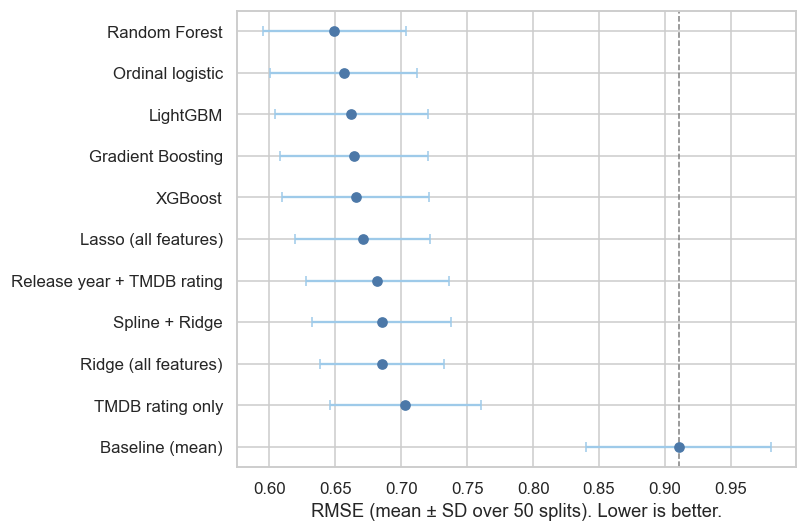

In [17]:
def corrected_t(diff, test_frac=0.2):
    # 5-fold CV: test/train ratio is 0.2 / 0.8
    k = len(diff)
    var = diff.var(ddof=1)
    t = diff.mean() / np.sqrt((1 / k + test_frac / (1 - test_frac)) * var)
    return t, 2 * stats.t.sf(abs(t), k - 1)

base = res[BASE]['rmse']
rows = []
for name, r in res.items():
    d = base - r['rmse']
    t, p = corrected_t(d) if name != BASE else (np.nan, np.nan)
    rows.append({'model': name, 'RMSE': r['rmse'].mean(), 'RMSE_sd': r['rmse'].std(),
                 'MAE': r['mae'].mean(), 'R2': r['r2'].mean(),
                 'RMSE_gain': d.mean(), 'corrected_p': p})
tab = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
print(tab.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
y_pos = np.arange(len(tab))[::-1]
ax.errorbar(tab['RMSE'], y_pos, xerr=tab['RMSE_sd'], fmt='o', color='#4c78a8', ecolor='#9ecae9', capsize=3)
ax.axvline(tab.loc[tab['model'] == BASE, 'RMSE'].iloc[0], color='gray', ls='--', lw=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(tab['model'])
ax.set_xlabel('RMSE (mean ± SD over 50 splits). Lower is better.')
fig.tight_layout()
fig.savefig(FIG / '06_model_comparison.png')
plt.show()

Beating the baseline is a low bar. The real question is whether the more complex models add anything over the **simple two-variable model** (release year + TMDB rating). I run the same corrected test against it. A positive difference means the model beats the simple one. I make 9 comparisons here, so I also adjust the p-values with Holm's method.

In [18]:
from statsmodels.stats.multitest import multipletests
simple = res[SIMPLE]['rmse']
rows = []
for name in res:
    if name in (BASE, SIMPLE):
        continue
    d = simple - res[name]['rmse']
    t, p = corrected_t(d)
    rows.append({'model': name, 'diff': d.mean(), 'p': p})
cmp = pd.DataFrame(rows)
cmp['p_holm'] = multipletests(cmp['p'], method='holm')[1]
print(cmp.sort_values('diff', ascending=False).round(3).to_string(index=False))

               model   diff     p  p_holm
       Random Forest  0.033 0.040   0.318
    Ordinal logistic  0.026 0.020   0.176
            LightGBM  0.020 0.307   1.000
   Gradient Boosting  0.018 0.252   1.000
             XGBoost  0.016 0.377   1.000
Lasso (all features)  0.011 0.284   1.000
      Spline + Ridge -0.003 0.886   1.000
Ridge (all features) -0.004 0.831   1.000
    TMDB rating only -0.021 0.042   0.318


### 3. Nested cross-validation: an honest "best model" score

If I picked the model with the lowest RMSE in the table above and reported that RMSE, I'd be optimistic: out of 11 models I may simply have picked the luckiest one. In nested cross-validation, in every outer split:

1. Inside the outer training set, a separate 5-fold CV chooses each model's settings and compares the models with each other,
2. The winning model is refit on the whole outer training set,
3. It is measured on the untouched outer test set.

This estimates the real error *including* the model-selection step. It's computationally heavy, so I keep the outer loop at 5 folds repeated twice (10 outer splits).

In [19]:
cands = {
    SIMPLE: (models[SIMPLE], {}),
    'Ridge (all features)': (models['Ridge (all features)'], {}),
    'Spline + Ridge': (models['Spline + Ridge'], {'columntransformer__spl__n_knots': [4, 6]}),
    'Ordinal logistic': (models['Ordinal logistic'], {}),
    'Random Forest': (models['Random Forest'], {'randomforestregressor__min_samples_leaf': [3, 8],
                                                'randomforestregressor__max_features': [0.33, 0.66]}),
    'Gradient Boosting': (models['Gradient Boosting'], {'gradientboostingregressor__max_depth': [2, 3],
                                                        'gradientboostingregressor__n_estimators': [150, 300]}),
    'XGBoost': (models['XGBoost'], {'xgbregressor__max_depth': [2, 3],
                                    'xgbregressor__n_estimators': [200, 400]}),
    'LightGBM': (models['LightGBM'], {'lgbmregressor__num_leaves': [4, 8],
                                      'lgbmregressor__n_estimators': [200, 400]}),
}

outer = RepeatedKFold(n_splits=5, n_repeats=2, random_state=7)
inner = KFold(5, shuffle=True, random_state=SEED)
nested = []
for i, (tr, te) in enumerate(outer.split(X), 1):
    Xtr, ytr, Xte, yte = X.iloc[tr], y[tr], X.iloc[te], y[te]
    inner_scores = {}
    fitted = {}
    for name, (est, grid) in cands.items():
        gs = GridSearchCV(clone(est), grid, cv=inner, scoring='neg_root_mean_squared_error', n_jobs=1)
        gs.fit(Xtr, ytr)
        inner_scores[name] = -gs.best_score_
        fitted[name] = gs
    win = min(inner_scores, key=inner_scores.get)
    pred = fitted[win].predict(Xte)       # GridSearchCV refit the best setting on the whole outer training set
    base_pred = np.full(len(yte), ytr.mean())
    simple_pred = fitted[SIMPLE].predict(Xte)
    nested.append({'split': i, 'winner': win, 'inner_RMSE': inner_scores[win],
                   'outer_RMSE': np.sqrt(np.mean((pred - yte) ** 2)),
                   'simple_model_outer_RMSE': np.sqrt(np.mean((simple_pred - yte) ** 2)),
                   'baseline_outer_RMSE': np.sqrt(np.mean((base_pred - yte) ** 2))})
    print(f"split {i:2d}: winner {win:28s} inner {inner_scores[win]:.3f}  outer {nested[-1]['outer_RMSE']:.3f}")

nested = pd.DataFrame(nested)
print(f"\nNested CV RMSE (selection included): {nested['outer_RMSE'].mean():.3f} (±{nested['outer_RMSE'].std():.3f})")
print(f"Simple model on the same splits:      {nested['simple_model_outer_RMSE'].mean():.3f}")
print(f"Baseline on the same splits:          {nested['baseline_outer_RMSE'].mean():.3f}")
print(f"Outer minus inner score (optimism):   {(nested['outer_RMSE'] - nested['inner_RMSE']).mean():+.3f}")
print('\nTimes each model won:')
print(nested['winner'].value_counts())

split  1: winner Random Forest                inner 0.660  outer 0.638


split  2: winner Gradient Boosting            inner 0.650  outer 0.584


split  3: winner Random Forest                inner 0.629  outer 0.759


split  4: winner XGBoost                      inner 0.607  outer 0.778


split  5: winner Random Forest                inner 0.688  outer 0.492


split  6: winner Ordinal logistic             inner 0.622  outer 0.789


split  7: winner Random Forest                inner 0.662  outer 0.563


split  8: winner XGBoost                      inner 0.657  outer 0.672


split  9: winner Ordinal logistic             inner 0.648  outer 0.686


split 10: winner Random Forest                inner 0.644  outer 0.662

Nested CV RMSE (selection included): 0.662 (±0.097)
Simple model on the same splits:      0.678
Baseline on the same splits:          0.908
Outer minus inner score (optimism):   +0.016

Times each model won:
winner
Random Forest        5
XGBoost              2
Ordinal logistic     2
Gradient Boosting    1
Name: count, dtype: int64


### 4. Coefficients of the ordinal model

I fit the ordinal logistic model on all the data and look at its coefficients. The features are standardised, so each coefficient is read "per one standard deviation increase". An odds ratio above 1 means that as the feature goes up, the odds of me landing on a higher rating step go up.

In [20]:
ord_full = OrdinalLogit().fit(X, y)
p = ord_full.res_.params
se = ord_full.res_.bse
k = len(ord_full.cols)
coef = pd.DataFrame({'coef': p.iloc[:k], 'std_err': se.iloc[:k], 'p': ord_full.res_.pvalues.iloc[:k]})
coef['odds_ratio'] = np.exp(coef['coef'])
coef['or_95_low'] = np.exp(coef['coef'] - 1.96 * coef['std_err'])
coef['or_95_high'] = np.exp(coef['coef'] + 1.96 * coef['std_err'])
print(coef.round(3))
print('\nStandard deviations (what 1 SD means):')
print(ord_full.sd_.round(2))

                    coef  std_err      p  odds_ratio  or_95_low  or_95_high
year              -0.445    0.116  0.000       0.641      0.511       0.805
tmdb_vote_average  1.635    0.158  0.000       5.130      3.766       6.987
log_votes         -0.449    0.156  0.004       0.638      0.470       0.867
is_english        -0.164    0.135  0.225       0.849      0.651       1.106

Standard deviations (what 1 SD means):
year                 14.71
tmdb_vote_average     0.69
log_votes             1.68
is_english            0.40
dtype: float64


### 5. How close are the predictions to reality?

The predictions of the model with the lowest RMSE in the main comparison, each made without having seen that film (5-fold cross-validation).

Model with the lowest RMSE: Random Forest


With these 5 folds: RMSE 0.650, MAE 0.505, Spearman 0.675
Share of predictions within half a star: 58%, within one star: 89%


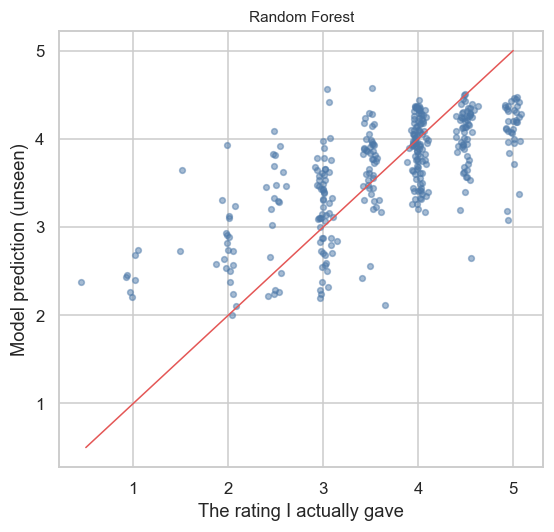

In [21]:
best_name = tab.loc[~tab['model'].isin([BASE])].iloc[0]['model']
print('Model with the lowest RMSE:', best_name)

oof = cross_val_predict(models[best_name], X, y, cv=KFold(5, shuffle=True, random_state=SEED))
print(f'With these 5 folds: RMSE {np.sqrt(np.mean((oof - y) ** 2)):.3f}, '
      f'MAE {np.mean(np.abs(oof - y)):.3f}, Spearman {stats.spearmanr(oof, y)[0]:.3f}')
print(f'Share of predictions within half a star: {(np.abs(oof - y) <= 0.5).mean():.0%}, '
      f'within one star: {(np.abs(oof - y) <= 1.0).mean():.0%}')

fig, ax = plt.subplots(figsize=(5.2, 5))
jit = np.random.default_rng(SEED).normal(0, 0.05, len(y))
ax.scatter(y + jit, oof, s=14, alpha=0.5, color='#4c78a8')
ax.plot([0.5, 5], [0.5, 5], color='#e45756', lw=1)
ax.set_xlabel('The rating I actually gave')
ax.set_ylabel('Model prediction (unseen)')
ax.set_title(best_name, fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '07_predicted_vs_actual.png')
plt.show()

### 6. Which features matter?

Permutation importance: how much the error goes up when a feature's values are shuffled in the test set. In each fold I fit the model on the training part and measure on the test part, and report the average over the 5 folds. Correlated features (release year and genres, for example) can share importance, so the ranking is a rough guide.

tmdb_vote_average    0.280
year                 0.080
g_Science_Fiction    0.008
log_popularity       0.007
g_Adventure          0.006
log_votes            0.006
g_Action             0.005
is_english           0.005
g_Drama              0.002
g_Thriller           0.002
n_genres             0.001
g_Mystery            0.001
dtype: float64


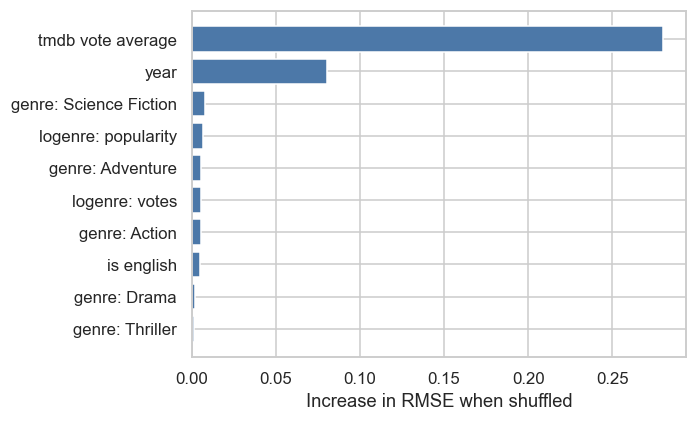

In [22]:
imps = []
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(X):
    m = clone(models[best_name]).fit(X.iloc[tr], y[tr])
    pi = permutation_importance(m, X.iloc[te], y[te], scoring='neg_root_mean_squared_error',
                                n_repeats=20, random_state=SEED)
    imps.append(pi.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False)
print(imp.head(12).round(3))

top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(top.index.str.replace('g_', 'genre: ').str.replace('_', ' '), top.values, color='#4c78a8')
ax.set_xlabel('Increase in RMSE when shuffled')
fig.tight_layout()
fig.savefig(FIG / '08_feature_importance.png')
plt.show()

### 7. Loved it or not?

I ask the same question as a classification: can I tell apart the films I gave 4 or more ("loved it")? The metric is ROC AUC, where 0.5 is a coin flip and 1 is perfect.

In [23]:
from xgboost import XGBClassifier
yc = df['loved'].values
print(f'Share of "loved it": {yc.mean():.0%}')
cv_c = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
clfs = {
    'Baseline': DummyClassifier(strategy='prior'),
    'Logistic regression (L2)': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                              LogisticRegression(C=0.3, max_iter=2000)),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=2, subsample=0.7,
                             colsample_bytree=0.7, min_child_weight=3, random_state=SEED, n_jobs=1),
}
for name, m in clfs.items():
    s = cross_validate(m, X, yc, cv=cv_c, scoring=['roc_auc', 'accuracy', 'balanced_accuracy'])
    print(f"{name:26s} AUC {s['test_roc_auc'].mean():.3f} (±{s['test_roc_auc'].std():.3f})  "
          f"accuracy {s['test_accuracy'].mean():.3f}  balanced accuracy {s['test_balanced_accuracy'].mean():.3f}")

Share of "loved it": 55%


Baseline                   AUC 0.500 (±0.000)  accuracy 0.555  balanced accuracy 0.500


Logistic regression (L2)   AUC 0.829 (±0.047)  accuracy 0.760  balanced accuracy 0.755


XGBoost                    AUC 0.843 (±0.046)  accuracy 0.757  balanced accuracy 0.751


### 8. Ranking my watchlist

I fit the lowest-RMSE model on all 355 films and apply it to the films on my watchlist that I haven't rated yet. The error is roughly the RMSE above, so I take the overall direction of the ranking seriously, not any single prediction.

In [24]:
films = pd.read_csv(ROOT / 'data' / 'processed' / 'films_enriched.csv')
wl = pd.read_csv(ROOT / 'data' / 'raw' / 'watchlist.csv')
rated = set(df['uri'])
cand = films[films['uri'].isin(wl['Letterboxd URI']) & ~films['uri'].isin(rated)].copy()
print('On my watchlist:', len(wl), '| with TMDB data and not rated yet:', len(cand))

final = clone(models[best_name]).fit(X, y)
cand['prediction'] = np.clip(final.predict(build(cand)), 0.5, 5).round(2)
cand = cand.sort_values('prediction', ascending=False)
out = cand[['name', 'year', 'prediction', 'genres', 'directors', 'tmdb_vote_average']]
out.to_csv(ROOT / 'reports' / 'watchlist_predictions.csv', index=False, encoding='utf-8-sig')

print('\nTop 15 predictions:')
print(out.head(15).to_string(index=False))
print('\nBottom 5 predictions:')
print(out.tail(5).to_string(index=False))

On my watchlist: 249 | with TMDB data and not rated yet: 247



Top 15 predictions:
              name  year  prediction                        genres            directors  tmdb_vote_average
           Persona  1966        4.64                         Drama       Ingmar Bergman              8.100
  The Seventh Seal  1957        4.60                 Fantasy|Drama       Ingmar Bergman              8.135
          Harakiri  1962        4.60          Action|Drama|History     Masaki Kobayashi              8.470
 Wild Strawberries  1957        4.60                         Drama       Ingmar Bergman              8.073
          Close-Up  1990        4.59                   Crime|Drama     Abbas Kiarostami              7.985
           Le Trou  1960        4.59          Drama|Thriller|Crime       Jacques Becker              8.226
     Autumn Sonata  1978        4.59                         Drama       Ingmar Bergman              7.971
Children of Heaven  1997        4.56                  Drama|Family         Majid Majidi              7.869
      Come and S

### 9. A classic 80/20 split

Every result so far comes from cross-validation. Here I also try the classic route: I set aside 20% of the films at the very start and don't look at them until model selection is finished.

1. I split the films into 80% training (284 films) and 20% test (71 films). The split is stratified by rating step so the rating distribution stays the same in both sets.
2. I choose the model and its settings **on the training set only**, with 5-fold cross-validation repeated 3 times.
3. I refit the winning model on the whole training set and measure it on the test set **once**.

71 films is a small test set, so I also report a bootstrap confidence interval for the test RMSE.

In [25]:
from sklearn.model_selection import train_test_split

strata = pd.cut(y, [0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0], include_lowest=True)   # 2.5 and below is one step
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=strata)
Xtr, Xte, ytr, yte = X.iloc[idx_tr], X.iloc[idx_te], y[idx_tr], y[idx_te]

print(f'Train: {len(ytr)} films, mean {ytr.mean():.2f} | Test: {len(yte)} films, mean {yte.mean():.2f}')
dist = pd.DataFrame({'train': pd.Series(ytr).value_counts(normalize=True),
                     'test': pd.Series(yte).value_counts(normalize=True)}).sort_index().fillna(0)
print((dist * 100).round(1).T.to_string())
print('Do the two sets differ in rating distribution? Mann-Whitney p =', round(stats.mannwhitneyu(ytr, yte).pvalue, 3))

Train: 284 films, mean 3.66 | Test: 71 films, mean 3.68
       0.5  1.0  1.5  2.0  2.5   3.0   3.5   4.0   4.5  5.0
train  0.4  2.5  0.7  4.6  6.0  16.9  13.4  29.2  16.5  9.9
test   0.0  0.0  0.0  9.9  4.2  16.9  14.1  28.2  16.9  9.9
Do the two sets differ in rating distribution? Mann-Whitney p = 0.996


#### Model selection (training set only)

In [26]:
cv_tr = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
sel = {}
for name, (est, grid) in cands.items():
    gs = GridSearchCV(clone(est), grid, cv=cv_tr, scoring='neg_root_mean_squared_error', n_jobs=1)
    gs.fit(Xtr, ytr)                     # GridSearchCV refits the best setting on the whole training set
    sel[name] = gs
    print(f'{name:28s} within-train CV RMSE {-gs.best_score_:.3f}  settings: {gs.best_params_ or "fixed"}')

winner = min(sel, key=lambda k: -sel[k].best_score_)
print(f'\nChosen model: {winner}')

Release year + TMDB rating   within-train CV RMSE 0.687  settings: fixed


Ridge (all features)         within-train CV RMSE 0.697  settings: fixed


Spline + Ridge               within-train CV RMSE 0.691  settings: {'columntransformer__spl__n_knots': 4}


Ordinal logistic             within-train CV RMSE 0.657  settings: fixed


Random Forest                within-train CV RMSE 0.650  settings: {'randomforestregressor__max_features': 0.66, 'randomforestregressor__min_samples_leaf': 3}


Gradient Boosting            within-train CV RMSE 0.663  settings: {'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__n_estimators': 150}


XGBoost                      within-train CV RMSE 0.662  settings: {'xgbregressor__max_depth': 3, 'xgbregressor__n_estimators': 200}


LightGBM                     within-train CV RMSE 0.664  settings: {'lgbmregressor__n_estimators': 200, 'lgbmregressor__num_leaves': 4}

Chosen model: Random Forest


#### One measurement on the test set

I compare the chosen model with the baseline that predicts the training mean and with the simple two-variable model. I get the intervals of the differences by resampling the same test films (paired bootstrap).

In [27]:
def scores(pred, yt):
    return {'RMSE': np.sqrt(np.mean((pred - yt) ** 2)), 'MAE': np.mean(np.abs(pred - yt)),
            'R2': 1 - np.sum((yt - pred) ** 2) / np.sum((yt - yt.mean()) ** 2),
            'Spearman': stats.spearmanr(pred, yt)[0] if np.ptp(pred) > 0 else np.nan}

preds = {
    f'{winner} (chosen)': sel[winner].predict(Xte),
    SIMPLE: sel[SIMPLE].predict(Xte),
    'Baseline (training mean)': np.full(len(yte), ytr.mean()),
}
print(pd.DataFrame({k: scores(p, yte) for k, p in preds.items()}).T.round(3).to_string())

# paired bootstrap: resample the same test films
B = 5000
boot_idx = np.random.default_rng(SEED).integers(0, len(yte), size=(B, len(yte)))
def rmse_b(p):
    e = (p[boot_idx] - yte[boot_idx]) ** 2
    return np.sqrt(e.mean(axis=1))
p_win = preds[f'{winner} (chosen)']
r_win = rmse_b(p_win)
r_base = rmse_b(preds['Baseline (training mean)'])
r_simple = rmse_b(preds[SIMPLE])
q = lambda a: np.quantile(a, [0.025, 0.975]).round(3)
print(f'\n95% interval of the chosen model\'s test RMSE: {q(r_win)}')
print(f'Baseline minus chosen model:     mean {np.mean(r_base - r_win):.3f}, 95% interval {q(r_base - r_win)}')
print(f'Simple model minus chosen model: mean {np.mean(r_simple - r_win):.3f}, 95% interval {q(r_simple - r_win)}')

print(f'\nShare of predictions within half a star: {(np.abs(p_win - yte) <= 0.5).mean():.0%}, '
      f'within one star: {(np.abs(p_win - yte) <= 1.0).mean():.0%}')

                             RMSE    MAE     R2  Spearman
Random Forest (chosen)      0.666  0.520  0.396     0.609
Release year + TMDB rating  0.683  0.540  0.365     0.597
Baseline (training mean)    0.857  0.717 -0.001       NaN

95% interval of the chosen model's test RMSE: [0.541 0.79 ]
Baseline minus chosen model:     mean 0.193, 95% interval [0.058 0.33 ]
Simple model minus chosen model: mean 0.018, 95% interval [-0.031  0.067]

Share of predictions within half a star: 56%, within one star: 90%


#### Overfitting check

For the same model: the error on the training set, the within-train cross-validation error and the test error, side by side. If the training error is far below the other two, the model is memorising the training data. I show this for every candidate. The test column here was not used for selection, it's only shown for transparency.

                     model  train (memorised)  within-train CV  test
             Random Forest              0.382            0.650 0.666
          Ordinal logistic              0.644            0.657 0.666
                   XGBoost              0.411            0.662 0.678
         Gradient Boosting              0.412            0.663 0.664
                  LightGBM              0.506            0.664 0.665
Release year + TMDB rating              0.675            0.687 0.683
            Spline + Ridge              0.584            0.691 0.693
      Ridge (all features)              0.623            0.697 0.664


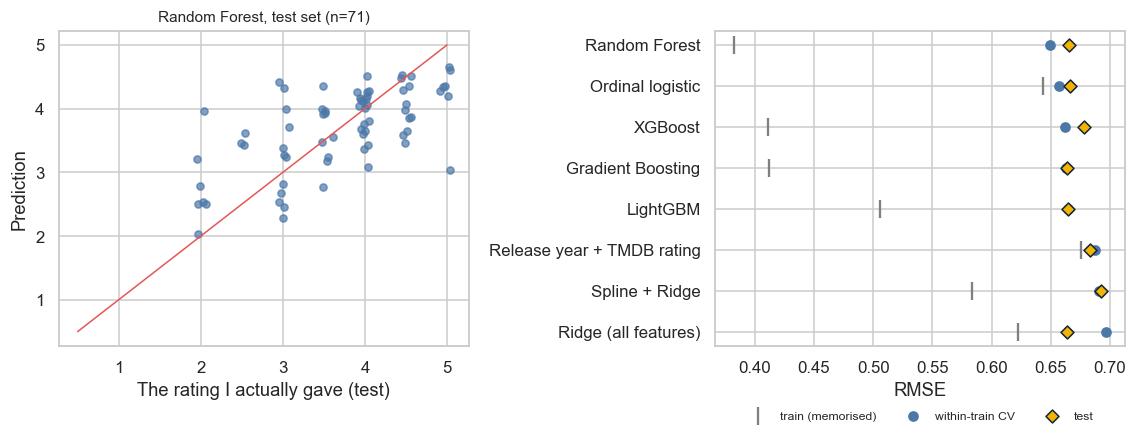

In [28]:
rows = []
for name, gs in sel.items():
    rows.append({'model': name,
                 'train (memorised)': np.sqrt(np.mean((gs.predict(Xtr) - ytr) ** 2)),
                 'within-train CV': -gs.best_score_,
                 'test': np.sqrt(np.mean((gs.predict(Xte) - yte) ** 2))})
of = pd.DataFrame(rows).sort_values('within-train CV').reset_index(drop=True)
print(of.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
jit = np.random.default_rng(SEED).normal(0, 0.05, len(yte))
ax.scatter(yte + jit, p_win, s=22, alpha=0.7, color='#4c78a8')
ax.plot([0.5, 5], [0.5, 5], color='#e45756', lw=1)
ax.set_xlabel('The rating I actually gave (test)')
ax.set_ylabel('Prediction')
ax.set_title(f'{winner}, test set (n={len(yte)})', fontsize=10)
ax = axes[1]
pos = np.arange(len(of))
ax.scatter(of['train (memorised)'], pos, marker='|', s=140, color='gray', label='train (memorised)')
ax.scatter(of['within-train CV'], pos, marker='o', color='#4c78a8', label='within-train CV')
ax.scatter(of['test'], pos, marker='D', color='#f2b400', edgecolor='#14233a', label='test')
ax.set_yticks(pos)
ax.set_yticklabels(of['model'])
ax.invert_yaxis()
ax.set_xlabel('RMSE')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIG / '09_holdout_test.png')
plt.show()

### 10. What came out of it?

Apart from section 9, these results come from 5-fold cross-validation repeated 10 times on 355 films. The error measure is RMSE, read in the units of the rating scale.

**I can make predictions.** The baseline that predicts my mean rating for everyone has an RMSE of 0.91. A linear model with only the TMDB rating brings it down to 0.70, and adding release year to 0.68. Every model is significantly better than the baseline (corrected p < 0.001).

**Model ranking.** Random Forest had the lowest RMSE (0.649), followed by ordinal logistic regression (0.656), LightGBM (0.662), Gradient Boosting (0.664) and XGBoost (0.665). The differences between these five are far smaller than the standard deviations (about 0.055), so in practice they sit in the same place. Adding splines didn't improve on the simple model (0.685), so the effects of release year and TMDB rating are roughly linear.

**Can we beat the simple model?** Compared with the "release year + TMDB rating" model, Random Forest is 0.033 and ordinal logistic 0.026 better in RMSE. On their own these differences are borderline significant (corrected p = 0.040 and 0.020), but I compared nine models, and after a Holm adjustment both lose significance (0.32 and 0.18). For XGBoost and LightGBM even the unadjusted p is around 0.3. The honest summary: the extra features and flexible models seem to give a small improvement, but I can't prove it with this sample.

**Nested cross-validation.** When model and setting selection happen inside each outer split, the RMSE is 0.662 (±0.097). On the same splits the simple model gets 0.678 and the baseline 0.908. The inner scores are on average 0.016 more optimistic than the outer ones. So "pick the best model and report it" says 0.649, while the honest estimate that includes the selection step is about 0.66. Random Forest won 5 of the outer splits, XGBoost 2, ordinal logistic 2 and Gradient Boosting 1. The winner changing from split to split shows these models really are close to each other.

**The classic 80/20 split says the same thing.** Selection on the 284-film training set again picked Random Forest (within-train CV RMSE 0.650). On the 71 films I set aside at the start and hadn't looked at until then, the test RMSE is 0.666 (bootstrap 95% interval 0.54 to 0.79), MAE 0.52 and R² 0.40. 56% of the predictions are within half a star and 90% within one star. On the same test films the baseline got 0.857: the difference is 0.19 and its interval excludes zero (0.06 to 0.33). Against the simple model the difference is 0.018 and its interval includes zero (-0.03 to 0.07). So in a single hold-out test too, the model clearly beats the baseline but can't be told apart from the simple model. The test error (0.666) is very close to the cross-validation estimates (0.65 to 0.66), which shows the cross-validation results weren't optimistic.

**Overfitting.** Random Forest has an error of 0.38 on its own training set, so it largely memorises the training films. But the within-train CV (0.65) and the test error (0.67) are close to each other, so the memorising doesn't distort the estimate of how well it generalises. That's expected for tree models. Ordinal logistic regression shows almost no gap (train 0.64, CV 0.66, test 0.67): a model with four parameters isn't flexible enough to memorise.

**The ordinal model is the most interesting result.** With only four features (release year, TMDB rating, log vote count, English or not) it comes very close to Random Forest, and its coefficients can be interpreted:
- A one standard deviation increase in TMDB rating (0.69 points) multiplies the odds of me landing on a higher rating step by 5.1 (95% interval 3.8 to 7.0).
- When a film is one standard deviation (about 15 years) newer, the odds drop to 0.64 (0.51 to 0.81).
- Holding the TMDB rating fixed, one standard deviation more votes drops the odds to 0.64 (0.47 to 0.87). Of two films with the same TMDB rating, I like the less known one more.
- Being in English isn't significant once these are held fixed (p = 0.23). The language difference from the exploratory analysis seems to come largely from those films being older and better rated on TMDB.

**Feature importance.** Permutation importance for Random Forest tells the same story: TMDB rating (0.28) and release year (0.08) dominate, every genre is below 0.01.

**Error margin.** On a film it hasn't seen, Random Forest is off by about half a star on average. 58% of the predictions are within half a star of my actual rating and 89% within one star. The Spearman correlation between prediction and actual rating is 0.68, so it's better at ranking films than at hitting individual ratings.

**Loved it or not?** Separating the 4+ films, logistic regression gets an AUC of 0.83 and XGBoost 0.84 (baseline 0.50). Accuracy is around 76% for both. The gap between them is far below the standard deviation (0.046).

**Watchlist.** I ranked 247 films with Random Forest. At the top are older films with high TMDB ratings by directors like Bergman, Kobayashi, Kiarostami, Tarkovsky and Kieślowski (Persona, The Seventh Seal, Harakiri, Wild Strawberries). At the bottom are new action, sci-fi and horror films (Salvation, Megalopolis, Longlegs). The list is in `reports/watchlist_predictions.csv`.

#### Limitations

- 355 films is not much. The differences between models are at the noise level, so the ranking shouldn't be read as definitive.
- The model can't separate "my taste" from "the TMDB average and the film's age". Films the crowd dislikes but I like will always be predicted wrong.
- I didn't use director, cast or keyword information. Most directors appear only once in 355 films. Turning these into text vectors could be a next step.
- Most films on my watchlist are well known. Predictions are less reliable for films with low TMDB ratings or few votes.